# Gen Z Money Spends —


---
## 1. Mount Google Drive & Set Workspace Path
Run this cell to connect Google Colab to your Google Drive. Follow the authorization prompt if asked.


In [1]:
# Mount Google Drive
from google.colab import drive
import os
import sys

drive.mount('/content/drive')

# Set your folder path on Google Drive
# Default: If you uploaded the folder 'google_colab_project' directly to 'My Drive'
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/google_colab_project'

# Auto-detection helper: if the folder was placed in another directory in Drive
if not os.path.exists(DRIVE_PROJECT_DIR):
    print("Default path not found. Searching for 'genz_money_spends.csv' in MyDrive...")
    found = False
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'genz_money_spends.csv' in files:
            DRIVE_PROJECT_DIR = root
            found = True
            print(f"✅ Found dataset folder at: {DRIVE_PROJECT_DIR}")
            break
    if not found:
        print("⚠️ Could not locate 'genz_money_spends.csv' automatically.")
        print("Please set DRIVE_PROJECT_DIR to your exact Drive path (e.g., '/content/drive/MyDrive/YourFolder').")
else:
    print(f"✅ Google Drive mounted successfully! Working directory: {DRIVE_PROJECT_DIR}")

# Define file paths
RAW_DATA_PATH = os.path.join(DRIVE_PROJECT_DIR, 'genz_money_spends.csv')
CLEANED_DATA_PATH = os.path.join(DRIVE_PROJECT_DIR, 'genz_money_spends_cleaned.csv')


Mounted at /content/drive
✅ Google Drive mounted successfully! Working directory: /content/drive/MyDrive/google_colab_project


---
##  2: Import Libraries & Configure Visuals


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configurations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("✅ Libraries imported successfully! Pandas version:", pd.__version__)


✅ Libraries imported successfully! Pandas version: 2.2.3


---
##  3: Load the Raw Dataset from Google Drive


In [3]:
# Check if file exists and load
if os.path.exists(RAW_DATA_PATH):
    df_raw = pd.read_csv(RAW_DATA_PATH)
    print(f"✅ Raw dataset loaded successfully!")
    print(f"• Rows: {df_raw.shape[0]:,}")
    print(f"• Columns: {df_raw.shape[1]}")
    display(df_raw.head())
else:
    print(f"❌ File not found at: {RAW_DATA_PATH}")
    print("Please check your file path or upload 'genz_money_spends.csv' to your Google Drive folder.")


✅ Raw dataset loaded successfully!
• Rows: 1,700
• Columns: 15


,ID,Age,Income (USD),Rent (USD),Groceries (USD),Eating Out (USD),Entertainment (USD),Subscription Services (USD),Education (USD),Online Shopping (USD),Savings (USD),Investments (USD),Travel (USD),Fitness (USD),Miscellaneous (USD)
0,1,24,7131,544,494,303,81,21,1937,402,1587,619,886,154,291
1,2,21,5311,841,288,406,375,98,1660,262,145,2902,1032,237,296
2,3,25,4125,784,501,79,327,27,1146,586,2991,2407,1284,85,157
3,4,22,3882,421,254,298,38,88,1056,160,2157,4452,210,232,381
4,5,24,2941,424,154,475,384,15,1536,476,763,3004,1328,186,151


---
##  4: Data Quality Audit (Nulls, Duplicates, Types)


In [5]:
print("=== DATASET OVERVIEW ===")
df_raw.info()

print("\n=== MISSING VALUES PER COLUMN ===")
missing_summary = df_raw.isnull().sum()
print(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "✅ No missing values found!")

print("\n=== DUPLICATE ROWS CHECK ===")
exact_dupes = df_raw.duplicated().sum()
id_dupes = df_raw['ID'].duplicated().sum() if 'ID' in df_raw.columns else 0
print(f"Exact Duplicate Rows: {exact_dupes}")
print(f"Duplicate IDs: {id_dupes}")

print("\n=== NUMERICAL SUMMARY STATS ===")
display(df_raw.describe().round(2))

=== DATASET OVERVIEW ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1700 entries, 0 to 1699
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   ID                           1700 non-null   int64
 1   Age                          1700 non-null   int64
 2   Income (USD)                 1700 non-null   int64
 3   Rent (USD)                   1700 non-null   int64
 4   Groceries (USD)              1700 non-null   int64
 5   Eating Out (USD)             1700 non-null   int64
 6   Entertainment (USD)          1700 non-null   int64
 7   Subscription Services (USD)  1700 non-null   int64
 8   Education (USD)              1700 non-null   int64
 9   Online Shopping (USD)        1700 non-null   int64
 10  Savings (USD)                1700 non-null   int64
 11  Investments (USD)            1700 non-null   int64
 12  Travel (USD)                 1700 non-null   int64
 13  Fitness (USD)          

,ID,Age,Income (USD),Rent (USD),Groceries (USD),Eating Out (USD),Entertainment (USD),Subscription Services (USD),Education (USD),Online Shopping (USD),Savings (USD),Investments (USD),Travel (USD),Fitness (USD),Miscellaneous (USD)
count,1700.00,1700.00,1700.00,1700.00,1700.00,1700.00,1700.00,1700.00,1700.00,1700.0,1700.00,1700.00,1700.00,1700.00,1700.00
mean,850.50,22.45,4764.82,1155.63,357.14,272.06,209.12,55.89,1009.90,362.9,1557.37,2450.59,1017.13,158.45,208.72
std,490.89,2.92,1877.08,495.20,142.62,131.82,109.62,26.11,576.57,197.1,818.41,1461.92,557.02,82.09,109.90
min,1.00,18.00,1501.00,300.00,100.00,50.00,20.00,10.00,0.00,20.0,100.00,0.00,53.00,10.00,20.00
25%,425.75,20.00,3149.75,724.00,237.00,157.00,113.00,33.00,518.50,191.0,891.00,1189.25,554.50,88.00,112.00
50%,850.50,22.00,4743.00,1157.50,362.00,266.50,210.00,57.00,995.00,370.0,1563.50,2414.00,1014.50,158.00,207.50
75%,1275.25,25.00,6419.75,1589.75,482.25,387.25,303.25,79.00,1513.50,539.0,2222.25,3755.00,1481.25,230.00,301.00
max,1700.00,27.00,7994.00,1999.00,599.00,499.00,399.00,99.00,1996.00,699.0,2999.00,4999.00,1998.00,299.00,399.00


---
##  5: Data Cleaning & Standardisation
In this step, we:
1. Standardize column names to snake_case (e.g. `Income (USD)` $\rightarrow$ `income_usd`).
2. Remove duplicates (if any).
3. Validate numeric datatypes and ensure non-negative values.


In [6]:
# Make a working copy
df_clean = df_raw.copy()

# 1. Standardize column names
rename_map = {
    'ID': 'id',
    'Age': 'age',
    'Income (USD)': 'income_usd',
    'Rent (USD)': 'rent_usd',
    'Groceries (USD)': 'groceries_usd',
    'Eating Out (USD)': 'eating_out_usd',
    'Entertainment (USD)': 'entertainment_usd',
    'Subscription Services (USD)': 'subscription_services_usd',
    'Education (USD)': 'education_usd',
    'Online Shopping (USD)': 'online_shopping_usd',
    'Savings (USD)': 'savings_usd',
    'Investments (USD)': 'investments_usd',
    'Travel (USD)': 'travel_usd',
    'Fitness (USD)': 'fitness_usd',
    'Miscellaneous (USD)': 'miscellaneous_usd'
}
df_clean = df_clean.rename(columns=rename_map)

# 2. Drop duplicates if any
df_clean = df_clean.drop_duplicates(subset=['id'])

# 3. Handle any potential nulls
df_clean = df_clean.dropna()

# 4. Enforce integer / non-negative numeric constraints
num_cols = [c for c in df_clean.columns if c != 'id']
for c in num_cols:
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce').fillna(0).astype(int)
    df_clean[c] = df_clean[c].clip(lower=0)

print(f"✅ Data standardized. Cleaned dataset contains {df_clean.shape[0]} rows and {df_clean.shape[1]} columns.")
display(df_clean.head(3))


✅ Data standardized. Cleaned dataset contains 1700 rows and 15 columns.


,id,age,income_usd,rent_usd,groceries_usd,eating_out_usd,entertainment_usd,subscription_services_usd,education_usd,online_shopping_usd,savings_usd,investments_usd,travel_usd,fitness_usd,miscellaneous_usd
0,1,24,7131,544,494,303,81,21,1937,402,1587,619,886,154,291
1,2,21,5311,841,288,406,375,98,1660,262,145,2902,1032,237,296
2,3,25,4125,784,501,79,327,27,1146,586,2991,2407,1284,85,157


---
##  6: Feature Engineering (Financial Metrics & Personas)
We engineer rich domain-specific features essential for Gen Z spending analysis:
- `total_expenses_usd`: Sum of all spending categories.
- `essential_expenses_usd`: Rent, groceries, and education.
- `discretionary_expenses_usd`: Eating out, entertainment, shopping, subscriptions, travel, fitness, misc.
- `total_savings_investments_usd`: Savings + investments combined.
- `total_financial_outflow_usd`: All expenses + savings + investments.
- `net_cashflow_usd`: Income minus total living expenses.
- `savings_rate_pct`: (savings / income) * 100.
- `investment_rate_pct`: (investments / income) * 100.
- `expense_to_income_ratio`: total expenses / income.
- `age_group`: Age bracket categorization (18-20, 21-23, 24-27).
- `financial_persona`: Behavior cluster (Aggressive Wealth Builder, Balanced Planner, Deficit Spender, Lifestyle Focused).
- `is_expense_outlier`: 1 if total expense is an IQR outlier, else 0.


In [7]:
# Categorize expense streams
expense_cols = [
    'rent_usd', 'groceries_usd', 'eating_out_usd', 'entertainment_usd',
    'subscription_services_usd', 'education_usd', 'online_shopping_usd',
    'travel_usd', 'fitness_usd', 'miscellaneous_usd'
]
essential_cols = ['rent_usd', 'groceries_usd', 'education_usd']
discretionary_cols = [
    'eating_out_usd', 'entertainment_usd', 'subscription_services_usd',
    'online_shopping_usd', 'travel_usd', 'fitness_usd', 'miscellaneous_usd'
]

# Totals
df_clean['total_expenses_usd'] = df_clean[expense_cols].sum(axis=1)
df_clean['essential_expenses_usd'] = df_clean[essential_cols].sum(axis=1)
df_clean['discretionary_expenses_usd'] = df_clean[discretionary_cols].sum(axis=1)
df_clean['total_savings_investments_usd'] = df_clean['savings_usd'] + df_clean['investments_usd']
df_clean['total_financial_outflow_usd'] = df_clean['total_expenses_usd'] + df_clean['total_savings_investments_usd']

# Net Cashflow
df_clean['net_cashflow_usd'] = df_clean['income_usd'] - df_clean['total_expenses_usd']

# Rates & Ratios
df_clean['savings_rate_pct'] = np.round((df_clean['savings_usd'] / df_clean['income_usd']) * 100, 2)
df_clean['investment_rate_pct'] = np.round((df_clean['investments_usd'] / df_clean['income_usd']) * 100, 2)
df_clean['expense_to_income_ratio'] = np.round((df_clean['total_expenses_usd'] / df_clean['income_usd']), 2)
df_clean['discretionary_to_total_ratio'] = np.round((df_clean['discretionary_expenses_usd'] / df_clean['total_expenses_usd']), 2)

# Age Bracket
def get_age_group(age):
    if age <= 20:
        return '18-20 (College / Entry)'
    elif age <= 23:
        return '21-23 (Early Career)'
    else:
        return '24-27 (Established Gen-Z)'

df_clean['age_group'] = df_clean['age'].apply(get_age_group)

# Financial Persona Segmentation
def get_persona(row):
    wealth_rate = row['savings_rate_pct'] + row['investment_rate_pct']
    if row['expense_to_income_ratio'] > 1.0:
        return 'Deficit Spender'
    elif wealth_rate >= 50:
        return 'Aggressive Wealth Builder'
    elif wealth_rate >= 25:
        return 'Balanced Planner'
    else:
        return 'Lifestyle Focused'

df_clean['financial_persona'] = df_clean.apply(get_persona, axis=1)

# IQR Outlier Detection on Total Expenses
q25 = df_clean['total_expenses_usd'].quantile(0.25)
q75 = df_clean['total_expenses_usd'].quantile(0.75)
iqr = q75 - q25
lower = q25 - (1.5 * iqr)
upper = q75 + (1.5 * iqr)
df_clean['is_expense_outlier'] = ((df_clean['total_expenses_usd'] < lower) | (df_clean['total_expenses_usd'] > upper)).astype(int)

print(f"✅ Feature engineering complete! New dataset shape: {df_clean.shape}")
display(df_clean[['id', 'age', 'income_usd', 'total_expenses_usd', 'net_cashflow_usd', 'savings_rate_pct', 'financial_persona']].head())


✅ Feature engineering complete! New dataset shape: (1700, 28)


,id,age,income_usd,total_expenses_usd,net_cashflow_usd,savings_rate_pct,financial_persona
0,1,24,7131,5113,2018,22.25,Balanced Planner
1,2,21,5311,5495,-184,2.73,Deficit Spender
2,3,25,4125,4976,-851,72.51,Deficit Spender
3,4,22,3882,3138,744,55.56,Aggressive Wealth Builder
4,5,24,2941,5129,-2188,25.94,Deficit Spender


---
##  7: Exploratory Data Visualizations


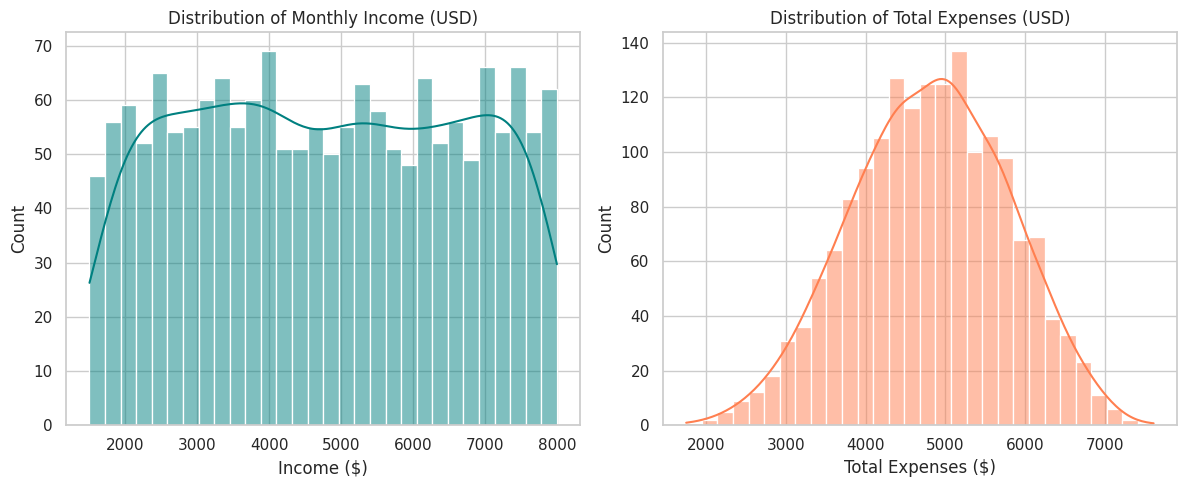

/tmp/ipykernel_4432/1621305953.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mean_spends.values, y=[c.replace('_usd', '').replace('_', ' ').title() for c in mean_spends.index], palette='mako')


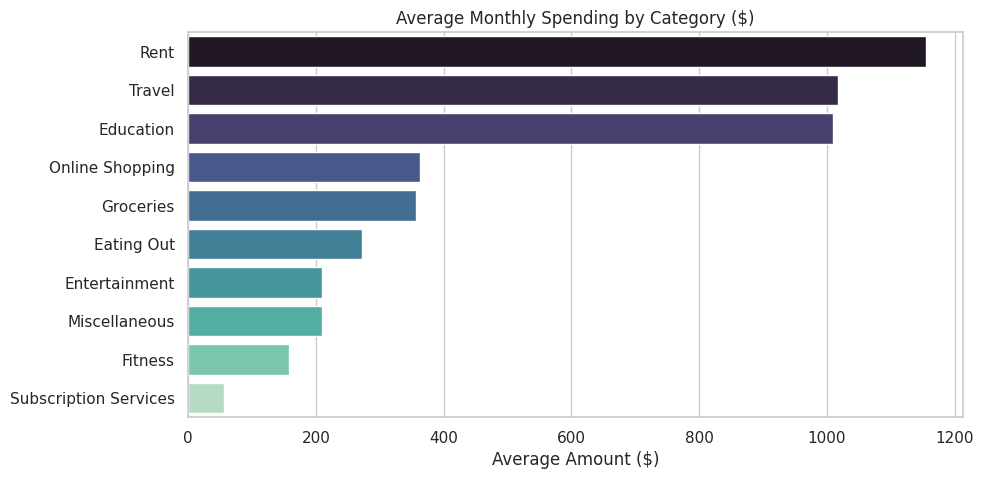

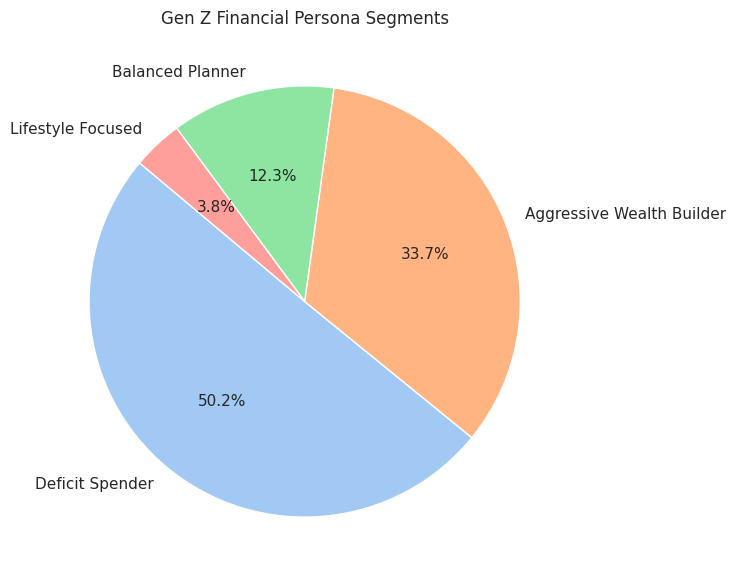

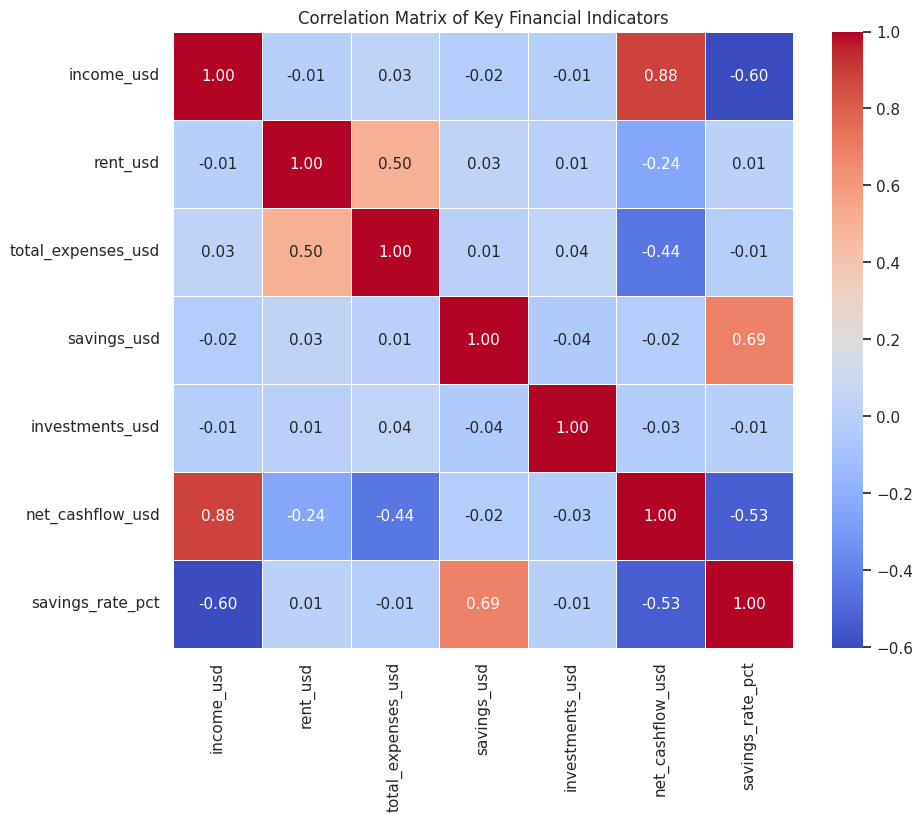

In [8]:
# 1. Income vs Total Expenses Distribution
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['income_usd'], kde=True, color='teal', bins=30)
plt.title("Distribution of Monthly Income (USD)")
plt.xlabel("Income ($)")

plt.subplot(1, 2, 2)
sns.histplot(df_clean['total_expenses_usd'], kde=True, color='coral', bins=30)
plt.title("Distribution of Total Expenses (USD)")
plt.xlabel("Total Expenses ($)")
plt.tight_layout()
plt.show()

# 2. Average Spend Across Categories
categories = [
    'rent_usd', 'groceries_usd', 'eating_out_usd', 'entertainment_usd',
    'subscription_services_usd', 'education_usd', 'online_shopping_usd',
    'travel_usd', 'fitness_usd', 'miscellaneous_usd'
]
mean_spends = df_clean[categories].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=mean_spends.values, y=[c.replace('_usd', '').replace('_', ' ').title() for c in mean_spends.index], palette='mako')
plt.title("Average Monthly Spending by Category ($)")
plt.xlabel("Average Amount ($)")
plt.show()

# 3. Financial Persona Distribution
plt.figure(figsize=(7, 7))
persona_counts = df_clean['financial_persona'].value_counts()
plt.pie(persona_counts, labels=persona_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=140)
plt.title("Gen Z Financial Persona Segments")
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_cols = ['income_usd', 'rent_usd', 'total_expenses_usd', 'savings_usd', 'investments_usd', 'net_cashflow_usd', 'savings_rate_pct']
sns.heatmap(df_clean[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Key Financial Indicators")
plt.show()


---
##   8: Export Cleaned Dataset to Google Drive & Direct Download


In [10]:
# Save directly to Google Drive
df_clean.to_csv(CLEANED_DATA_PATH, index=False)
print(f"🎉 SUCCESS: Cleaned dataset saved directly to Google Drive at:")
print(f"👉 {CLEANED_DATA_PATH}")

# Optional: Download directly to your local computer from Colab
try:
    from google.colab import files
    print("\nClicking below will also download the cleaned file to your local computer:")
    files.download(CLEANED_DATA_PATH)
except Exception as e:
    print(f"Note: Local browser download skipped ({e}). File is safely stored in Google Drive.")

🎉 SUCCESS: Cleaned dataset saved directly to Google Drive at:
👉 /content/drive/MyDrive/google_colab_project/genz_money_spends_cleaned.csv

Clicking below will also download the cleaned file to your local computer:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>